# 2. A campaign on a cluster

When every model is a batch job that takes hours, the campaign cannot call your code itself. Instead it lives in
a directory and moves one round at a time:

```
sagari next  my_campaign                       # writes rounds/round_000.csv
   ... run the models of that round with your own code, add model_id,chi2 to results.csv ...
sagari next  my_campaign --results results.csv # writes the next round, or reports "done"
```

This notebook plays both roles: it calls the command line through `sagari.cli.main` (identical to typing the
commands in a shell), and stands in for the cluster with a Python function. It also shows how failed models,
partial rounds, and a box narrowed mid-campaign are handled.

In [1]:
import shutil
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
import sagari as sg
from sagari.cli import main as sagari_cli
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False})
INK, BLUE, ORANGE, GRAY = "#222222", "#2a78d6", "#eb6834", "#9a9a9a"
UPS, MBH = r"$\Upsilon$", r"$M_\bullet$"
WORK = Path("cluster_campaign"); shutil.rmtree(WORK, ignore_errors=True); WORK.mkdir()

## The space file

The same parameters as a Schwarzschild campaign with a cored logarithmic halo. Write exponents with a sign
(`5.0e+9`): plain YAML reads `5.0e9` as a string (the package catches and converts it, but other tools may not).

In [2]:
(WORK / "space.yaml").write_text('''name: demo
parameters:
  upsilon:     {bounds: [2.0, 12.0]}
  mbh:         {bounds: [3.0e+7, 5.0e+9], scale: log}
  v_c:         {bounds: [0.0, 800.0]}
  r_c:         {bounds: [0.1, 30.0], scale: log}
  inclination: {value: 89.0}
''')
sagari_cli(["init", str(WORK / "campaign"), "--space", str(WORK / "space.yaml"),
                 "--converge-on", "mbh,upsilon", "--n-initial", "128", "--n-round", "64"])
print((WORK / "campaign" / "campaign.yaml").read_text()[:900])

created cluster_campaign/campaign/campaign.yaml: ParameterSpace(demo: mbh[3e+07, 5e+09, log], r_c[0.1, 30, log], upsilon[2, 12], v_c[0, 800]; fixed inclination=89)
converge on: mbh, upsilon; next: sagari next cluster_campaign/campaign
name: demo
sagari_version: 1.0.0
space:
  name: demo
  parameters:
    mbh:
      bounds:
      - 30000000.0
      - 5000000000.0
      scale: log
    r_c:
      bounds:
      - 0.1
      - 30.0
      scale: log
    upsilon:
      bounds:
      - 2.0
      - 12.0
      scale: linear
    v_c:
      bounds:
      - 0.0
      - 800.0
      scale: linear
    inclination:
      value: 89.0
settings:
  seed: 20260817
  n_initial: 128
  n_round: 64
  converge_on:
  - mbh
  - upsilon
  stop:
    frac: 0.2
    patience: 1
    min_rounds: 2
    max_rounds: 20
  sampler:
    kernel: matern52
    train_window: 30.0
    global_fraction: 0.35
  estimate:
    n_train_cap: 300
  errorbars:
    n_round: 128
    n_profile: 7
    n_train_cap: 1000
    sd_tol: 3.0
    frac: 

`campaign.yaml` holds the space and every setting (the defaults are those of the paper; here the round sizes
are halved to keep the notebook quick). Round 0 is the start of a scrambled Sobol sequence:

In [3]:
sagari_cli(["next", str(WORK / "campaign")])
r0 = pd.read_csv(WORK / "campaign" / "rounds" / "round_000.csv")
r0.head()

wrote cluster_campaign/campaign/rounds/round_000.csv: 128 models (search; sobol_global 128)
Evaluate them and add a row per model (model_id, chi2) to your results table; chi2 = nan for a failure.


,model_id,mbh,r_c,upsilon,v_c,inclination,stage
0,r000_0000,3.275266e+08,2.942406,2.610645,616.708115,89,sobol_global
1,r000_0001,1.833280e+09,0.108644,8.878052,181.699415,89,sobol_global
2,r000_0002,8.837736e+08,29.672747,5.009189,545.272690,89,sobol_global
3,r000_0003,4.396409e+07,1.107884,11.481953,253.135269,89,sobol_global
4,r000_0004,7.086820e+07,10.166567,7.985629,350.138380,89,sobol_global


## The cluster

Your code receives the rows of a round file and returns one χ² per row; it never needs to know about the
campaign. The stand-in below has two families of solutions that trade stellar mass, halo and black hole against
each other, scatter of σ = 10, and a region where models fail (very high Υ with a strong halo).

The results table needs `model_id` and `chi2`. A failed model is written as `nan`. If your code rounds the
parameters it was given, add them as columns too and they replace the proposed values.

In [4]:
def cluster(rows, seed):
    u = np.log10(rows["mbh"].values) - 8.3
    y = rows["upsilon"].values
    v = rows["v_c"].values / 800
    rc = np.log10(rows["r_c"].values)
    a = 1000 + 40 * (u + 0.25 * (y - 6.0)) ** 2 + 6 * (y - 6.0) ** 2 + 60 * (v - 0.28) ** 2 + 30 * (rc + 0.43) ** 2
    b = 1004 + 40 * (u + 0.2 * (y - 7.6)) ** 2 + 6 * (y - 7.6) ** 2 + 60 * (v - 0.24) ** 2 + 10 * (rc - 0.04) ** 2
    chi2 = np.minimum(a, b) + np.random.default_rng(seed).normal(0, 10, len(rows))
    chi2[(y > 10) & (v > 0.6)] = np.nan
    return chi2

def run_round(i, results=None):
    rows = pd.read_csv(WORK / "campaign" / "rounds" / f"round_{i:03d}.csv")
    new = pd.DataFrame({"model_id": rows["model_id"], "chi2": cluster(rows, seed=i)})
    out = pd.concat([results, new]) if results is not None else new
    out.to_csv(WORK / "results.csv", index=False, na_rep="nan")
    return out

results = run_round(0)
results.tail(3)

,model_id,chi2
125,r000_0125,1195.697586
126,r000_0126,1127.851885
127,r000_0127,1037.299404


`next` refuses while a round still has models without results. This is the usual state while jobs are still
in the queue:

In [5]:
partial = results.iloc[:-5]; partial.to_csv(WORK / "partial.csv", index=False, na_rep="nan")
try:
    sagari_cli(["next", str(WORK / "campaign"), "--results", str(WORK / "partial.csv")])
except RuntimeError as e:
    print("refused:", e)

refused: round(s) [0] have models without results; evaluate them first (a failed model counts as evaluated: give it chi2 = nan)


## The search

Each call writes the next round: 65% placed by feasibility-weighted Expected Improvement, 35% continuing the
Sobol sequence, plus verification points around any isolated low model. We loop until the campaign says
`done`.

In [6]:
c = sg.Campaign(WORK / "campaign")
i = 0
while True:
    d = c.next_round(WORK / "results.csv")
    if d is None:
        break
    i = d.attrs["round"]
    print(f"round {i}: {d.attrs['phase']:8s} {len(d)} models  {d['stage'].value_counts().to_dict()}")
    results = run_round(i, results)

round 1: search   64 models  {'gp_ei_local': 26, 'sobol_global_continuation': 22, 'gp_ei_verify': 16}


round 2: search   64 models  {'gp_ei_local': 42, 'sobol_global_continuation': 22}


round 3: errorbar 128 models  {'errorbar': 128}


In [7]:
st = c.status(WORK / "results.csv")

ParameterSpace(demo: mbh[3e+07, 5e+09, log], r_c[0.1, 30, log], upsilon[2, 12], v_c[0, 800]; fixed inclination=89)
4 rounds, 384 models proposed, 384 evaluated (11 failed, 0 outside the current box)
  round 0 (128 models): mbh 6.711e+07-7.059e+08; upsilon 5.504-8.403; chi2_min 1003.5, T 8.8
  round 1 (192 models): mbh 7.226e+07-7.263e+08; upsilon 5.398-8.423; chi2_min 1003.2, T 9.0  moves {'mbh': 0.032, 'upsilon': 0.035}
  round 2 (256 models): mbh 7.242e+07-7.719e+08; upsilon 5.309-8.503; chi2_min 1004.8, T 9.9  moves {'mbh': 0.026, 'upsilon': 0.028}  -> stopping rule met
  error-bar round 3: out-of-sample rms z 1.04 over 128 models (3.1% above +2, 4.7% below -2); worst latent sd 2.85 (tol 3.0), worst end move 0.187  -> done
next: done


The search stopped once the monitored ranges of M_BH and Υ settled; the error-bar rounds then filled the
acceptable region and the profiles. Their **out-of-sample** test is the main check that the surrogate can be
trusted: its prediction for every model was saved in the round file before the model ran.

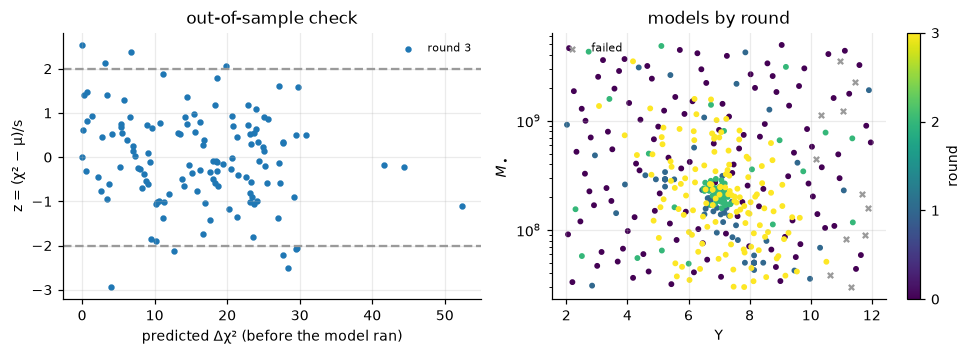

In [8]:
eb = [m for m in c.rounds() if m["phase"] == "errorbar"]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
j = c.results_table(WORK / "results.csv")
for m in eb:
    t = j[j["round"] == m["round"]]
    z = (t["chi2"] - t["pred_mu"]) / t["pred_sd"]
    ax[0].scatter(t["pred_mu"] - t["pred_mu"].min(), z, s=10, label=f"round {m['round']}")
ax[0].axhline(2, ls="--", color=GRAY); ax[0].axhline(-2, ls="--", color=GRAY)
ax[0].set(xlabel="predicted Δχ² (before the model ran)", ylabel="z = (χ² − μ)/s", title="out-of-sample check")
ax[0].legend(fontsize=7)
ok = j["chi2"].notna()
sc = ax[1].scatter(j.loc[ok, "upsilon"], j.loc[ok, "mbh"], c=j.loc[ok, "round"], s=8, cmap="viridis")
ax[1].scatter(j.loc[~ok, "upsilon"], j.loc[~ok, "mbh"], marker="x", s=12, color=GRAY, label="failed")
ax[1].set(yscale="log", xlabel=UPS, ylabel=MBH, title="models by round"); ax[1].legend(fontsize=7, loc="upper left")
fig.colorbar(sc, ax=ax[1], label="round", ticks=sorted(j["round"].unique()))
plt.tight_layout()

## Narrowing the box during a campaign

In the paper, the M86 search found a solution with an unphysically low stellar M/L and the floor on Υ was raised
mid-campaign. Edit the bounds in `campaign.yaml`: models outside the new box stay in the count but no longer
enter any surrogate, and the monitoring history is recomputed for the new box, so the stopping rule compares
like with like.

In [9]:
doc = yaml.safe_load((WORK / "campaign" / "campaign.yaml").read_text())
doc["space"]["parameters"]["upsilon"]["bounds"] = [4.0, 12.0]
(WORK / "campaign" / "campaign.yaml").write_text(yaml.safe_dump(doc, sort_keys=False))
st = sg.Campaign(WORK / "campaign").status(WORK / "results.csv", verbose=False)
print(f"{st['n_outside_box']} of {st['n_proposed']} models now lie outside the box and are left out of the fits")

36 of 384 models now lie outside the box and are left out of the fits


## The result

`sagari posterior` samples the posterior on the final surrogate and writes the samples and a JSON summary
(plug-in and surrogate-marginalized quantiles, and with `--profiles` the Δχ² profile intervals).

In [10]:
_ = sagari_cli(["posterior", str(WORK / "campaign"), "--results", str(WORK / "results.csv"),
                 "--out", str(WORK / "posterior"), "--nsteps", "6000", "--burn", "1000", "--profiles"])

surrogate: 336 training models, scatter sigma_chi2 = 10.04


plug-in posterior: 30000 samples (acceptance 0.35) -> cluster_campaign/posterior/posterior_samples.csv


  plug_in               mbh: 2.182e+08 (+1.27e+08 / -8.02e+07)
  plug_in               r_c: 0.9265 (+1.19 / -0.501)
  plug_in           upsilon: 7.026 (+0.834 / -1.02)
  plug_in               v_c: 208.8 (+109 / -106)
  marginalized          mbh: 2.16e+08 (+1.31e+08 / -8.56e+07)
  marginalized          r_c: 0.8795 (+1.32 / -0.514)
  marginalized      upsilon: 6.969 (+0.896 / -1.02)
  marginalized          v_c: 204.7 (+119 / -114)
  profile               mbh: dchi2<=1: 1.334e+08-3.559e+08; dchi2<=4: 8.723e+07-5.792e+08; dchi2<=10: 5.293e+07-9.262e+08
  profile               r_c: dchi2<=1: 0.4061-3.089; dchi2<=4: 0.1969-6.816; dchi2<=10: 0.1-16.39
  profile           upsilon: dchi2<=1: 5.665-8.136; dchi2<=4: 5.116-8.592; dchi2<=10: 4.607-9.069
  profile               v_c: dchi2<=1: 68.84-315; dchi2<=4: 0-438.1; dchi2<=10: 0-559.9
summary -> cluster_campaign/posterior/summary.json


### Connecting your own pipeline

All your code has to do is turn a round file into jobs and turn finished jobs into a results table.
`examples/sco_runalls.py` does exactly that for the Fortran orbit-superposition pipeline of the paper: it writes a
`runallt` commands file for a round and collects the `cres.*` files of a `res/` directory into a results table.
For other codes, the same two functions are a few lines each.